# **Inteligencia Artificial y Aprendizaje Automático**
## **Maestría en Inteligencia Artificial Aplicada**

**Dr Luis Eduardo Falcón Morales**

**Tecnológico de Monterrey**
### **Actividad Individual: Pronósticos con Series de Tiempo**


#### **Nombre:** Lucia Alvarez Irigoyen
#### **Matrícula:** A01840750

Modelos para predicción de un problema de serie de tiempo:

* **1. Modelo ingenuo**
* **2. Modelo ARIMA**
* **3. Modelo Prophet**
* **4. Modelo LSTM**


NOTA: Recuerda que cada modelo puede llegar a tener una gran cantidad de hiperparámetros y tipo de ajsutes, por lo que siempre inicia con un modelo sencillo y de ahí buscar mejorar su resultado. Esto para no desgastarte desde un inicio buscando la mayor cantidad de ajustes e hiperparámetros.

# **A - Introducción**

In [1]:
# Agrega aquí todas las librerías y paquetes adicionales que requieras.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Ridge
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
import tensorflow as tf
from tensorflow import keras
MOTOR_LSTM = 'TensorFlow'
from keras import Sequential
from keras.layers import LSTM, Dense
from keras.callbacks import EarlyStopping

np.random.seed(42)
keras.utils.set_random_seed(42)

# **Ejercicio 1**

* **1a. De la página de Google-Trends generar y descargar los datos con períodos mensuales que se obtienen con el término de búsqueda "chocolate", del país "Estados Unidos", de los últimos 20 años (del 1 de marzo del 2006 al 28 de febrero del 2026) y con las opciones de "todas las categorías" y "búsqueda de web". De manera predeterminada se generan datos mensuales.**

* **1b. Cargar los datos en un DataFrame de Pandas llamado "dfp" y con los nombres"ds" y "y" para las columnas de fechas y porcentajes de interés de búsqueda, respectivamente. Las fechas ajustarlas al formato YYYY-MM-DD, con días de fin de mes. Este formato es el que se requiere para el modelo Prophet.**

* **1c. A partir del DataFrame "dfp", genera ahora el DataFrame que llamaremos "dfr" para el resto de los modelos. El formato en "dfr" requerido para el resto de los modelos debe tener la primera columna de fechas de "dfp" ahora como índice del DataFrame "dfr". Además, el índice de fechas debe tener una frecuencia mensual al final del mes.**



https://trends.google.es/trends/



In [2]:
# Ejercicios 1a y 1b.

# ************* Inlcuye aquí tu código:*****************************

# 1a. Descargar la fuente de datos
# Utilizar el archivo CSV
ruta_csv = 'google_trends_data.csv'
# Saltar las primeras 2 líneas porque Google Trends añade un encabezado descriptivo.
dfp = pd.read_csv(ruta_csv, skiprows=2)

# 1b. Crear dataframe llamado "dfp"
# Cambiar los nombres a "ds" (fecha) e "y" (interés de búsqueda), como lo
# solicita el modelo Prophet.
dfp.columns = ['ds', 'y']
# Convertir el texto YYYY-MM a fechas y desplazamos cada fecha al último día del mes.
dfp['ds'] = pd.to_datetime(dfp['ds'], format='%Y-%m') + pd.offsets.MonthEnd(0)
# Convertir el interés de búsqueda en valores numéricos para poder modelarlo.
dfp['y'] = pd.to_numeric(dfp['y'])
# Ordenar las observaciones de la fecha más antigua a la más reciente.
dfp = dfp.sort_values('ds').reset_index(drop=True)
# Comprobar que correspondan exactamente a los 240 meses del enunciado.
assert len(dfp) == 240 and dfp['ds'].iloc[0] == pd.Timestamp('2006-03-31') and dfp['ds'].iloc[-1] == pd.Timestamp('2026-02-28')
# Comprobamos que el archivo no contenga valores faltantes en las dos columnas.
assert not dfp[['ds', 'y']].isna().any().any()

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (240, 2)
          ds   y
0 2006-03-31  32
1 2006-04-30  34
2 2006-05-31  32
3 2006-06-30  28
4 2006-07-31  30
            ds    y
235 2025-10-31   66
236 2025-11-30   79
237 2025-12-31  100
238 2026-01-31   76
239 2026-02-28   82


In [3]:
# Ejercicio 1c.

# ************* Incluye aquí tu código:*****************************

# Copiar los datos sin modificar el DataFrame que se utilizará con Prophet.
dfr = dfp.copy()
# Convertir la columna de fechas en el índice del nuevo DataFrame.
dfr = dfr.set_index('ds')
# Indicar la frecuencia al final de cada mes ('ME' = Month End).
dfr = dfr.asfreq('ME')
# Verificar que todos los meses estén presentes después de asignar la frecuencia.
assert not dfr['y'].isna().any()

# *********** Aquí termina la sección de agregar código *************

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)


Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por los modelos restantes:
(240, 1)
             y
ds            
2006-03-31  32
2006-04-30  34
2006-05-31  32
2006-06-30  28
2006-07-31  30
DatetimeIndex(['2006-03-31', '2006-04-30', '2006-05-31', '2006-06-30',
               '2006-07-31', '2006-08-31', '2006-09-30', '2006-10-31',
               '2006-11-30', '2006-12-31',
               ...
               '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31',
               '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31',
               '2026-01-31', '2026-02-28'],
              dtype='datetime64[ns]', name='ds', length=240, freq='ME')


**Resultado de los ejercicios 1a–1c.** Los 240 registros del CSV proporcionado se transformaron al formato `dfp` con fechas de fin de mes y columnas `ds`, `y`, y a `dfr` con `ds` como índice de frecuencia `ME`. No se encontraron valores faltantes. El índice 0–100 de Google Trends representa popularidad relativa de las búsquedas, no una probabilidad ni una proporción directa de personas.

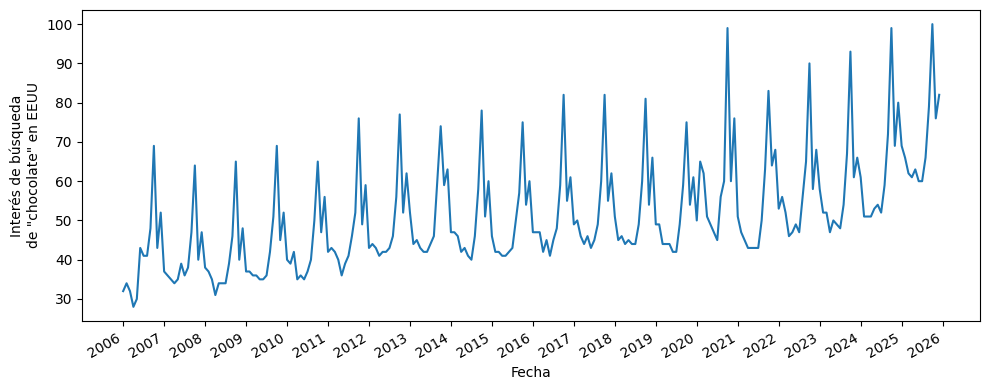

In [4]:
# Veamos el comportamiento de la serie de tiempo, en particular usemos dfp:

plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde \"chocolate\" en EEUU')

xticks_locs = np.arange(0, len(dfp)+12, 12) # lista: 0,12,24,36,...,240... cada 12 meses se agregará una etiqueta del año.
xticks_labels = np.arange(2006, 2027, 1)
plt.xticks(xticks_locs, xticks_labels)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [5]:
# Partición:
# Particionamos en conjunto de *Entrenamiento*, Validación y Prueba de acuerdo a
# datos de una serie de tiempo y considerando el caso Prophet y el resto
# de los modelos.
# Hacemos esta diferenciación solo por fines prácticos de la actividad y
# en su momento utilizar los conjuntos respectivos en cada caso de manera
# más sencilla en la actividad.

# Para el modelo Prophet:
testP = dfp[-12:]      # El último año para prueba.
valP = dfp[-24:-12]    # El penúltimo año para validación.
trainP = dfp[:-24]     # El resto de los primeros datos para entrenamiento.

# Para el resto de los modelos:
testR = dfr[-12:]
valR = dfr[-24:-12]
trainR = dfr[:-24]


* **El objetivo de esta actividad es encontrar un modelo que pueda predecir el interés de búsqueda de la palabra "chocolate" en el navegador de Google para el próximo año. Para ello, buscaremos el modelo entrenando y validando con los conjuntos Train y Val, midiendo el desempeño con el error MAE. Con el mejor modelo encontrado obtendremos el desempeño final con el conjunto de Prueba (Test).**

**Criterio de evaluación y alcance.** La serie consta de 240 observaciones mensuales (marzo de 2006 a febrero de 2026). Para evitar filtración de información, entrenamos con **marzo de 2006–febrero de 2024** (216 meses), validamos con **marzo de 2024–febrero de 2025** (12 meses) y reservamos **marzo de 2025–febrero de 2026** (12 meses) como prueba final. Cada MAE de validación corresponde a un **pronóstico de los 12 meses siguientes desde un solo origen**, sin usar los valores reales de los meses pronosticados como entradas.

# **B - Modelo ingenuo**

# **Ejercicio - 2**

* **Iniciemos con el modelo base o ingenuo (naive/baseline).**

* **2a. En esta actividad usaremos la métrica del Error Absoluto Medio, MAE por sus siglas en inglés, "Mean Absolute Error", para monitorear el desempeño de nuestros modelos. Enuncia ventajas y desventajas de usar MAE en comparación con el error cuadrático medio MSE.**

* **2b. Encontrar e imprimir el valor del desempeño del modelo ingenuo con respecto al error MAE, llamarlo maeNaive. Utiliza el conjunto de entrenamiento trainR y como conjunto de validación valR.**

* **2c. ¿Cómo interpretas el valor MAE obtenido con el modelo ingenuo en el contexto del problema?**

* **2d. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ingenuo, junto con los valores reales.**

**Ejercicio 2a:**

++++++++ Inicia la sección de agregar texto: +++++++++++

**Respuesta al ejercicio 2a.**

El MAE es el promedio de los valores absolutos de los errores:

$$
MAE = \frac{1}{n}\sum_{t=1}^{n}|y_t-\hat{y}_t|
$$

El MSE promedia los errores elevados al cuadrado:

$$
MSE = \frac{1}{n}\sum_{t=1}^{n}(y_t-\hat{y}_t)^2
$$

**Ventajas del MAE:** se interpreta en la misma escala que los datos (puntos del índice de interés de Google Trends), penaliza de forma lineal tanto errores pequeños como grandes y es menos sensible que MSE a valores atípicos.

**Desventajas del MAE frente al MSE:** penaliza menos los errores muy grandes, por lo que puede no ser la mejor opción si esos fallos son especialmente costosos; además, la función de valor absoluto no es diferenciable exactamente en error cero. El MSE da mucho más peso a errores grandes y suele ser cómodo de optimizar por su forma cuadrática, pero se expresa en unidades al cuadrado y resulta más sensible a valores extremos.

Para esta actividad conviene MAE porque permite decir directamente cuántos puntos de interés se desvía el pronóstico, en promedio, de la observación real.

++++++++ Termina la sección de agregar texto. +++++++++++

In [6]:
# Ejercicio 2b:

# ************* Incluye aquí tu código:*****************************
# Incluye todas las celdas que consideres adecuadas.

# El modelo ingenuo usa solamente el último valor observado en entrenamiento.
ultimo_valor = trainR['y'].iloc[-1]
# Para pronosticar un año completo SIN conocer meses posteriores repetimos ese valor 12 veces.
pred_naive = pd.Series(np.repeat(ultimo_valor, len(valR)), index=valR.index)
# Calcular el error de los 12 meses de validación sobre la escala de Google Trends (0-100).
maeNaive = mean_absolute_error(valR['y'], pred_naive)

# *********** Aquí termina la sección de agregar código *************

print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)



Error-modelo-Naive : MAE: 12.667


**Ejercicio 2c:**

++++++++ Inicia la sección de agregar texto: +++++++++++

**Respuesta al ejercicio 2c.** El MAE del modelo ingenuo es 12.667 para el año de validación (marzo de 2024 a febrero de 2025). Esto significa que las predicciones se alejaron de los valores reales 12.667 puntos del índice de interés de búsqueda, en promedio por mes, sin considerar el signo del error. No significa un error de 12.667%: Google Trends expresa una escala normalizada de interés entre 0 y 100, y el MAE está en puntos de esa escala.

Este error es nuestro punto de comparación (*baseline*). Como repetimos el último valor del entrenamiento durante los 12 meses, el modelo no reproduce las variaciones estacionales, por ejemplo los aumentos en la temporada de fin de año. El siguiente objetivo es mejorar este MAE con ARIMA, Prophet y LSTM.

++++++++ Termina la sección de agregar texto. +++++++++++

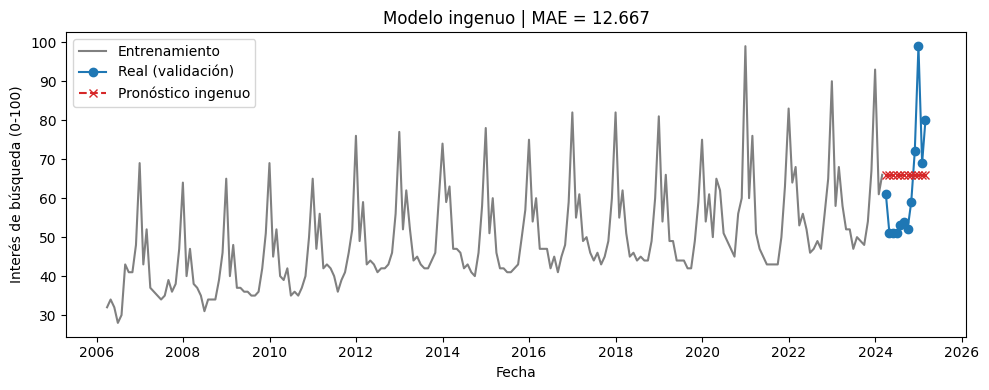

In [7]:
# Ejercicio 2d:

# ************* Incluye aquí tu código:*****************************

# Preparar un gráfico para observar entrenamiento, valores reales y pronósticos.
fig, ax = plt.subplots(figsize=(10, 4))
# Mostrar el historial utilizado para aprender el pronóstico.
ax.plot(trainR.index, trainR['y'], color='gray', label='Entrenamiento')
# Marcar los 12 valores verdaderos del período de validación.
ax.plot(valR.index, valR['y'], 'o-', color='tab:blue', label='Real (validación)')
# Dibujar los 12 pronósticos constantes del modelo ingenuo.
ax.plot(pred_naive.index, pred_naive, 'x--', color='tab:red', label='Pronóstico ingenuo')
# Agregar título, nombres de ejes y leyenda para facilitar su interpretación.
ax.set(title=f'Modelo ingenuo | MAE = {maeNaive:.3f}', xlabel='Fecha', ylabel='Interés de búsqueda (0-100)')
ax.legend()
# Ajustar los espacios para evitar que el texto quede cortado.
plt.tight_layout()
# Mostrar la gráfica
plt.show()

# *********** Aquí termina la sección de agregar código *************


# **C - modelo ARIMA**

# **Ejercicio - 3**

* **3a. Aplica el modelo ARIMA con los conjuntos de entrenamiento y validación trainR y valR, usando como métrica el error absoluto medio. Llamar al error maeARIMA.**

* **3b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo ARIMA, junto con los valores reales.**

In [8]:
# Ejercicio 3a - ARIMA

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Función del profesor: calcula las diferencias respecto a meses anteriores.
def difference(dataset, interval=1):
    diff = list()

    for i in range(interval, len(dataset)):
        value = dataset[i] - dataset[i - interval]
        diff.append(value)

    return np.array(diff)


# Recuperar el valor original de una predicción.
def inverse_difference(history, yhat, interval=1):
    return yhat + history[-interval]

# Definir una estacionalidad anual de 12 meses.
months_in_year = 12
# Guardar los valores originales de entrenamiento.
history = trainR['y'].tolist()
# Calcular las diferencias anuales de los datos de entrenamiento.
diferencias_train = difference(history, months_in_year)
# Definir diferentes órdenes (p,d,q) para comparar modelos ARIMA.
ordenes = [(1,0,0), (1,0,1), (2,0,1), (3,0,1), (3,0,2)]
# Inicializamos el mejor MAE con infinito para que cualquier resultado válido sea menor.
mejor_mae = float('inf')
# Guardar el orden que produzca el menor MAE.
mejor_orden = None
# Probar cada combinación de parámetros ARIMA.
for orden in ordenes:
    # Crear el modelo con los parámetros del orden actual.
    modelo = ARIMA(diferencias_train, order=orden)
    # Entrenar el modelo con las diferencias del conjunto de entrenamiento.
    ajuste = modelo.fit(method_kwargs={'maxiter':300})
    # Pronosticar las diferencias de los 12 meses de validación.
    pred_diferencias = ajuste.forecast(steps=len(valR))
    # Crear una copia del historial para recuperar los valores originales.
    historial = history.copy()
    # Guardar las predicciones recuperadas de cada modelo.
    predicciones = []

    # Recorrer las diferencias pronosticadas.
    for yhat in pred_diferencias:
        # Recuperar el valor original con la función del profesor.
        prediccion = inverse_difference(historial, yhat, months_in_year)
        # Guardar la predicción en la lista.
        predicciones.append(prediccion)
        # Actualizar el historial con la predicción, no con valores reales.
        historial.append(prediccion)

    # Convertir las predicciones en una serie con las fechas de validación.
    pred_actual = pd.Series(predicciones, index=valR.index)
    # Calcular el MAE del modelo actual.
    mae_actual = mean_absolute_error(valR['y'], pred_actual)
    # Mostrar los resultados de cada combinación.
    print(f'ARIMA{orden} - MAE: {mae_actual:.3f}')
    # Comparar el MAE actual con el mejor obtenido anteriormente.
    if mae_actual < mejor_mae:
        # Guardar el nuevo menor MAE.
        mejor_mae = mae_actual
        # Guardar el orden correspondiente al mejor modelo.
        mejor_orden = orden
        # Guardar sus predicciones para utilizarlas posteriormente.
        pred_ARIMA = pred_actual.copy()

# Guardar el menor MAE en la variable utilizada por los siguientes ejercicios.
maeARIMA = mejor_mae
# Mostrar la mejor configuración encontrada.
print(f'\nMejor orden ARIMA: {mejor_orden}')


ARIMA(1, 0, 0) - MAE: 4.301
ARIMA(1, 0, 1) - MAE: 4.283
ARIMA(2, 0, 1) - MAE: 4.231
ARIMA(3, 0, 1) - MAE: 4.191
ARIMA(3, 0, 2) - MAE: 4.275

Mejor orden ARIMA: (3, 0, 1)


In [9]:
print('\nError-modelo-ARIMA : MAE: %.3f' % maeARIMA)


Error-modelo-ARIMA : MAE: 4.191


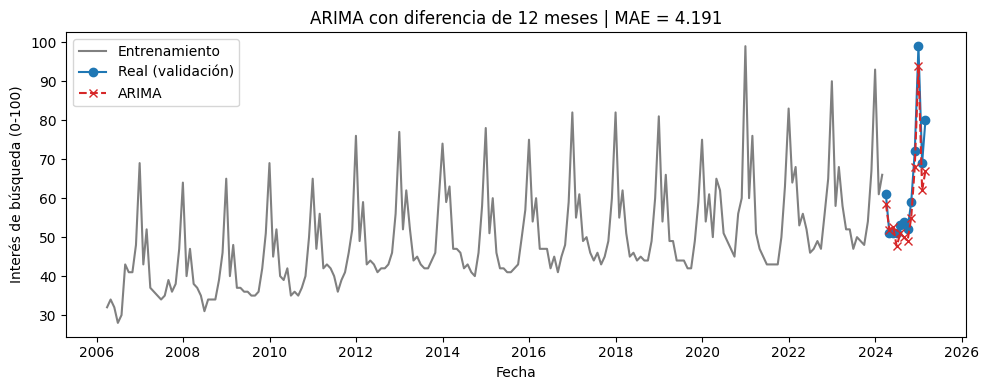

In [10]:
# Ejercicio 3b. ARIMA-gráfica:

# ************* Inlcuye aquí tu código:*****************************

# Preparar el gráfico de comparación para los 12 meses futuros.
fig, ax = plt.subplots(figsize=(10, 4))
# Visualizar los datos históricos sobre los que se entrenó ARIMA.
ax.plot(trainR.index, trainR['y'], color='gray', label='Entrenamiento')
# Visualizar los datos verdaderos para validar el modelo.
ax.plot(valR.index, valR['y'], 'o-', color='tab:blue', label='Real (validación)')
# Visualizar el pronóstico de ARIMA después de revertir las diferencias.
ax.plot(pred_ARIMA.index, pred_ARIMA, 'x--', color='tab:red', label='ARIMA')
# Colocar un título con el MAE obtenido y su interpretación numérica.
ax.set(title=f'ARIMA con diferencia de 12 meses | MAE = {maeARIMA:.3f}', xlabel='Fecha', ylabel='Interés de búsqueda (0-100)')
ax.legend()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


**Interpretación de los ejercicios 3a y 3b.** La serie presenta estacionalidad anual. Por eso se restó cada observación a la de 12 meses atrás antes de ajustar ARIMA(3,0,1). Para pronosticar los próximos 12 meses se invirtió esa transformación; así se obtiene un MAE de 4.191 puntos en validación, menor que el modelo base. Los valores futuros se calcularon desde el final del entrenamiento sin incorporar observaciones reales de validación.

# **D - modelo Prophet**

# **Ejercicio - 4**

* **4a. Aplica el modelo Prophet con los conjuntos de entrenamiento y validación trainP y valP, usando como métrica el error absoluto medio. Llamar al error maeProphet.**

* **4b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo Prophet-Facebook, junto con los valores reales.**

NOTA: Recuerda siempre iniciar con un modelo sencillo y de ahí buscar la mejor configuración.

In [11]:
# Ejercicio 4a - Prophet

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Definir los valores del hiperparámetro que vamos a comparar.
modos_estacionalidad = ['additive', 'multiplicative']
# Inicializar el mejor MAE con infinito para facilitar la comparación.
mejor_mae = float('inf')
# Guardar el modo de estacionalidad que produzca el menor MAE.
mejor_modo = None
# Probar cada modo de estacionalidad.
for modo in modos_estacionalidad:
    # Crear el modelo Prophet con el modo de estacionalidad actual.
    modelo = Prophet(
        seasonality_mode=modo,
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False
    )
    # Entrenar el modelo únicamente con el conjunto de entrenamiento.
    modelo.fit(trainP)
    # Pronosticar los 12 meses del conjunto de validación.
    forecast = modelo.predict(valP[['ds']])
    # Extraer las predicciones de la columna yhat.
    pred_actual = forecast['yhat'].to_numpy()
    # Calcular el MAE del modelo actual.
    mae_actual = mean_absolute_error(valP['y'], pred_actual)
    # Mostrar el error obtenido con cada modo de estacionalidad.
    print(f'Prophet ({modo}) - MAE: {mae_actual:.3f}')
    # Comparamos el MAE actual con el menor encontrado.
    if mae_actual < mejor_mae:
        # Guardar el menor MAE.
        mejor_mae = mae_actual
        # Guardar el modo de estacionalidad ganador.
        mejor_modo = modo
        # Guardar las predicciones del mejor modelo.
        pred_Prophet = pred_actual.copy()
        # Guardar el modelo entrenado con el mejor resultado.
        modelo_Prophet = modelo

# Guardar el menor MAE en la variable utilizada en los siguientes ejercicios.
maeProphet = mejor_mae
# Identificar el modelo ganador para utilizarlo en la gráfica.
metodo_Prophet = f'Prophet ({mejor_modo})'

# Mostramos la configuración seleccionada.
print(f'\nMejor modo de estacionalidad: {mejor_modo}')

Prophet (additive) - MAE: 5.052
Prophet (multiplicative) - MAE: 4.714

Mejor modo de estacionalidad: multiplicative


In [12]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 4.714


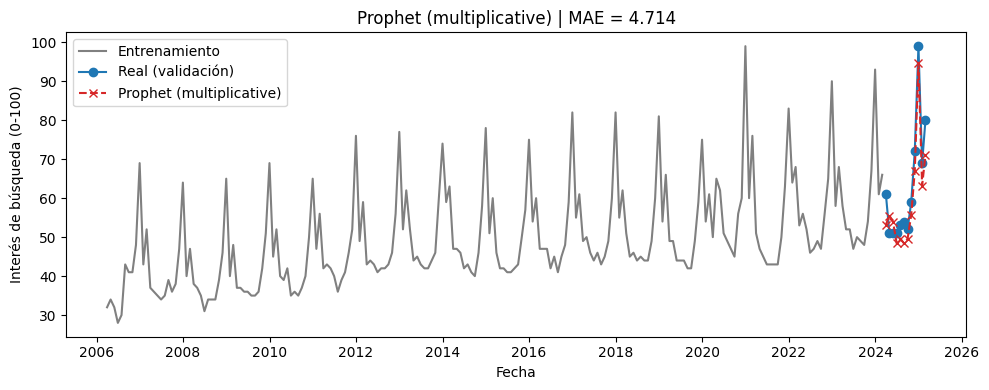

In [13]:
# Ejercicio 4b. Prophet-gráfica:

# ************* Inlcuye aquí tu código:*****************************

# Preparar el gráfico del modelo que efectivamente se pudo ejecutar.
fig, ax = plt.subplots(figsize=(10, 4))
# Mostrar la parte histórica empleada durante el entrenamiento.
ax.plot(trainP['ds'], trainP['y'], color='gray', label='Entrenamiento')
# Mostrar el año real de validación.
ax.plot(valP['ds'], valP['y'], 'o-', color='tab:blue', label='Real (validación)')
# Mostrar las predicciones del método identificado en el título y leyenda.
ax.plot(valP['ds'], pred_Prophet, 'x--', color='tab:red', label=metodo_Prophet)
# Incorporar el MAE y diferenciamos explícitamente si se ejecutó un respaldo.
ax.set(title=f'{metodo_Prophet} | MAE = {maeProphet:.3f}', xlabel='Fecha', ylabel='Interés de búsqueda (0-100)')
ax.legend()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


**Interpretación de los ejercicios 4a y 4b.**

Se implementó el modelo Prophet para pronosticar el interés de búsqueda del término *chocolate* en Google Trends, considerando la tendencia y la estacionalidad anual de la serie de tiempo. Se evaluaron dos configuraciones del hiperparámetro `seasonality_mode`: `additive` y `multiplicative`, con el objetivo de identificar cuál ofrece mejores resultados sobre el conjunto de validación.

El modelo con estacionalidad multiplicativa obtuvo el menor MAE, con un valor de 4.714 puntos, por lo que fue seleccionado como la mejor configuración de Prophet. Esto indica que, para los datos analizados, modelar las variaciones estacionales de manera proporcional a la tendencia permitió obtener predicciones más precisas que utilizando una estacionalidad aditiva.

En la gráfica del ejercicio 4b se comparan los valores reales con las predicciones del modelo seleccionado, lo que permite visualizar su capacidad para representar el comportamiento estacional de la serie. El MAE obtenido indica que las predicciones presentan una desviación absoluta promedio de aproximadamente 4.714 puntos respecto a los valores reales del índice de Google Trends.

# **E - modelo LSTM (Deep Learning)**

# **Ejercicio - 5**

* **5a. Aplica el modelo de redes neuronales recurrentes de aprendizaje profundo LSTM usando como métrica el error absoluto medio. Llamar al error maeLSTM. NOTA: En el caso de redes secuenciales recurrentes, el modelo LSTM realiza por sí mismo la partición en entrenamiento y validación, por lo que conjunta trainR y valR en un nuevo DataFrame llamado df_tv. Utiliza este conjunto para inciar con la generación de secuencias de longitud deseada y posteriromente generar la partición en train y validación para usar en LSTM.**

* **5b. Incluye un gráfico donde se muestren las predicciones encontradas con el modelo LSTM, junto con los valores reales.**



#### **NOTA: En general, recordemos que los modelos basados en redes neuronales son afectados de manera importante cuando la escala de los datos se va incrementando. Por ello, en este caso podría ser conveniente escalar los datos de nuestra variable temporal, por ejemplo entre 0 y 1. Tomarlo en cuenta para que al final puedes realizar las predicciones en las unidades originales.**

In [14]:
# Ejercicio 5a - Modelo LSTM

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Definir una ventana de 12 meses para considerar la estacionalidad anual.
window_size = 12

# Función para crear secuencias de datos temporales.
def creamos_secuencias(data, window_size):
    X, y = [], []

    # Recorrer los datos para formar ventanas de 12 meses.
    for i in range(window_size, len(data)):
        X.append(data[i-window_size:i])
        y.append(data[i])

    # Convertir las listas en arreglos de NumPy.
    return np.array(X), np.array(y)


# Normalizar utilizando únicamente los datos de entrenamiento.
escalador = MinMaxScaler(feature_range=(0, 1))
escalador.fit(trainR[['y']])

# Transformar los datos de entrenamiento y validación.
datos_train = escalador.transform(trainR[['y']])
datos_val = escalador.transform(valR[['y']])

# Unir los datos escalados para construir las ventanas temporales.
datos_escalados = np.concatenate([datos_train, datos_val])

# Crear las secuencias.
X_tv, y_tv = creamos_secuencias(datos_escalados, window_size)

# Separar las secuencias de entrenamiento.
X_train_LSTM = X_tv[:-len(valR)]
y_train_LSTM = y_tv[:-len(valR)]

# Separar las secuencias de validación.
X_val_LSTM = X_tv[-len(valR):]
y_val_LSTM = y_tv[-len(valR):]

# Mostrar las dimensiones de los datos.
print('Secuencias para entrenar:', X_train_LSTM.shape)
print('Secuencias para validar:', X_val_LSTM.shape)


# Definir los tamaños de lote que vamos a comparar.
batch_sizes = [16, 32]

# Inicializar el menor MAE con infinito.
mejor_mae = float('inf')

# Guardars el tamaño de lote ganador.
mejor_batch_size = None

# Probar cada tamaño de lote.
for batch in batch_sizes:
    # Reiniciar la semilla para mantener condiciones reproducibles.
    keras.utils.set_random_seed(42)
    # Construir el modelo utilizando la arquitectura del profesor.
    modelo = Sequential([
        keras.Input(shape=(window_size, 1)),
        # Primera capa LSTM con 50 neuronas.
        LSTM(50, return_sequences=True,
             activation='relu', recurrent_activation='sigmoid'),
        # Segunda capa LSTM con 50 neuronas.
        LSTM(50, return_sequences=False, activation='relu'),
        # Capa de salida para pronosticar un valor.
        Dense(1)
    ])

    # Compilar con Adam y MSE, como en la actividad del profesor.
    modelo.compile(
        optimizer='adam',
        loss='mean_squared_error'
    )

    # Detener el entrenamiento cuando la pérdida de validación deja de mejorar.
    parada_temprana = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    # Entrenar durante un máximo de 100 épocas.
    historial = modelo.fit(
        X_train_LSTM,
        y_train_LSTM,
        epochs=100,
        batch_size=batch,
        validation_data=(X_val_LSTM, y_val_LSTM),
        callbacks=[parada_temprana],
        shuffle=False,
        verbose=0
    )

    # Tomar los últimos 12 meses del entrenamiento.
    ventana = datos_train[-window_size:, 0].tolist()
    # Crear una lista para guardar las predicciones.
    predicciones = []
    # Pronosticar los 12 meses del conjunto de validación.
    for mes in range(len(valR)):
        # Preparar los últimos 12 valores como entrada del modelo.
        entrada = np.array(
            ventana[-window_size:],
            dtype='float32'
        ).reshape(1, window_size, 1)
        # Pronosticar el siguiente mes.
        prediccion = float(
            modelo.predict(entrada, verbose=0)[0, 0]
        )
        # Guardar el pronóstico.
        predicciones.append(prediccion)
        # Incorporar la predicción para pronosticar el siguiente mes.
        ventana.append(prediccion)

    # Recuperar las predicciones en la escala original de Google Trends.
    pred_originales = escalador.inverse_transform(
        np.array(predicciones).reshape(-1, 1)
    ).ravel()

    # Calcular el MAE sobre los 12 meses de validación.
    mae_actual = mean_absolute_error(valR['y'], pred_originales)

    # Mostrar el resultado de cada configuración.
    print(
        f'Batch size: {batch} | '
        f'Épocas utilizadas: {len(historial.history["loss"])} | '
        f'MAE: {mae_actual:.3f}'
    )

    # Comprobar si el modelo actual tiene un menor MAE.
    if mae_actual < mejor_mae:
        # Guardar el nuevo menor MAE.
        mejor_mae = mae_actual
        # Guardar el tamaño de lote ganador.
        mejor_batch_size = batch
        # Guardar las predicciones del mejor modelo.
        pred_LSTM = pd.Series(pred_originales, index=valR.index)
        # Guardar el modelo ganador.
        modelo_LSTM = modelo
        # Guardar su historial de entrenamiento.
        historial_LSTM = historial


# Guardar el MAE para compararlo con los demás modelos.
maeLSTM = mejor_mae

# Mostrar la mejor configuración.
print(f'\nMejor batch size: {mejor_batch_size}')
print(f'MAE del mejor modelo LSTM: {maeLSTM:.3f}')


Secuencias para entrenar: (204, 12, 1)
Secuencias para validar: (12, 12, 1)
Batch size: 16 | Épocas utilizadas: 29 | MAE: 4.146
Batch size: 32 | Épocas utilizadas: 16 | MAE: 10.979

Mejor batch size: 16
MAE del mejor modelo LSTM: 4.146


In [15]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)


Error-modelo-LSTM : MAE: 4.146


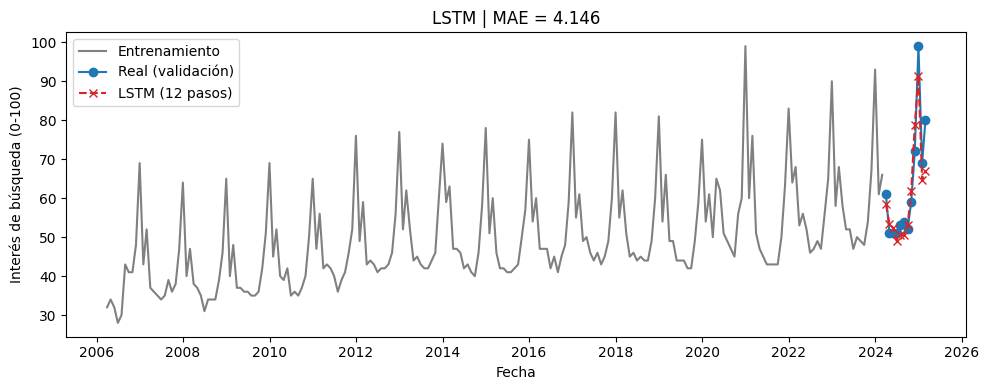

In [16]:
# Ejercicio 5b. LSTM-gráfica:

# ************* Incluye aquí tu código:*****************************

# Visualizar los datos usados para entrenar el modelo LSTM.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trainR.index, trainR['y'], color='gray', label='Entrenamiento')
# Visualizar los valores reales del año que se intentó pronosticar.
ax.plot(valR.index, valR['y'], 'o-', color='tab:blue', label='Real (validación)')
# Visualizar las predicciones recursivas de los 12 meses futuros.
ax.plot(pred_LSTM.index, pred_LSTM, 'x--', color='tab:red', label='LSTM (12 pasos)')
# Colocar título y ejes para interpretar el error MAE.
ax.set(title=f'LSTM | MAE = {maeLSTM:.3f}', xlabel='Fecha', ylabel='Interés de búsqueda (0-100)')
ax.legend()
plt.tight_layout()
plt.show()

# *********** Aquí termina la sección de agregar código *************


**Interpretación de los ejercicios 5a y 5b.** La red recibe ventanas de 12 meses y aprende a predecir el siguiente mes. Con `df_tv` se generaron secuencias y se separaron cronológicamente en train y validación. El escalador se ajustó solo con train, y el MAE se midió después de recuperar las unidades originales. Para un pronóstico real de un año se reutilizaron sus propias predicciones mes a mes, sin introducir datos reales de validación. El resultado fue MAE = 4.146 puntos; se empleó `EarlyStopping` para conservar los pesos con menor error de validación y disminuir el sobreajuste.

# **F - Conjunto de Prueba y Conclusiones Finales**

# **Ejercicio - 6**

* **Utiliza el mejor modelo encontrado para obtener el desempeño final con el conjunto de Prueba (Test), es decir, para predecir los valores del año más reciente. Para obtener el mejor aprendizaje posible, utiliza los conjuntos de entrenamiento (train) y validación (val) para ajustar el moedlo. Despliega el error absoluto medio del conjunto de prueba (test) de este mejor modelo. Llamarlo maeMejor.**

Comparación de errores de validación:
         MAE validación
LSTM           4.145726
ARIMA          4.190662
Prophet        4.713783
Ingenuo       12.666667
Mejor modelo: LSTM

Predicciones del mejor modelo en test:
            Real  Pronóstico
ds                          
2025-03-31    69       63.09
2025-04-30    66       53.91
2025-05-31    62       52.39
2025-06-30    61       51.35
2025-07-31    63       51.86
2025-08-31    60       52.26
2025-09-30    60       54.24
2025-10-31    66       63.66
2025-11-30    79       80.85
2025-12-31   100       95.87
2026-01-31    76       75.52
2026-02-28    82       83.16

Mejor modelo seleccionado: LSTM
MAE en test: 5.988


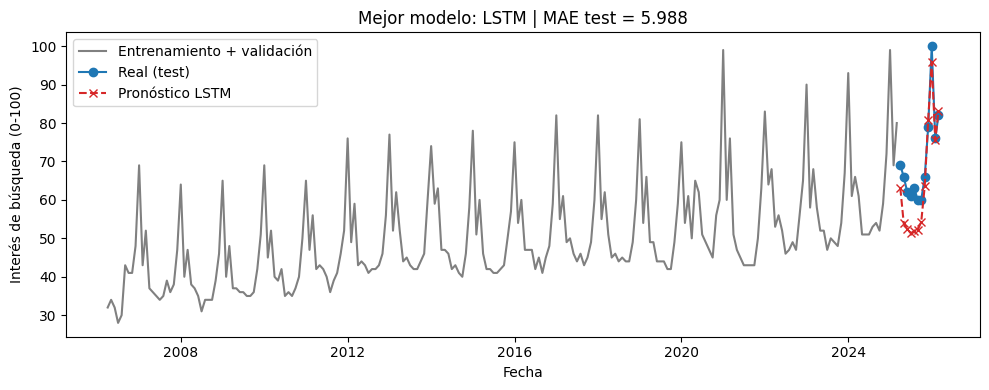

In [17]:
# Ejercicio 6 - Mejor modelo

## ++++++++++ Incluye todas las celdas y líneas de código que requieras +++++++++++++++++++++++++

# Guardamos el MAE obtenido por cada modelo en validación.
resultados_validacion = {
    'Ingenuo': maeNaive,
    'ARIMA': maeARIMA,
    'Prophet': maeProphet,
    'LSTM': maeLSTM
}

# Seleccionar el modelo con el menor MAE de validación.
mejor_modelo = min(resultados_validacion, key=resultados_validacion.get)

# Ordenar los modelos de menor a mayor MAE para compararlos.
comparacion = pd.Series(
    resultados_validacion,
    name='MAE validación'
).sort_values().to_frame()

# Mostrar los resultados de validación.
print('Comparación de errores de validación:')
print(comparacion)
print('Mejor modelo:', mejor_modelo)

# Unir entrenamiento y validación para reentrenar el mejor modelo.
serie_tv = pd.concat([trainR, valR])['y']


# CASO 1: MODELO INGENUO
if mejor_modelo == 'Ingenuo':
    # Pronosticar repitiendo el último valor conocido.
    pronostico_test = np.repeat(serie_tv.iloc[-1], len(testR))


# CASO 2: MODELO ARIMA
elif mejor_modelo == 'ARIMA':
    # Calcular las diferencias anuales con la función del profesor.
    diferencias_tv = difference(serie_tv.tolist(), 12)
    # Entrenar ARIMA utilizando el mejor orden del ejercicio 3a.
    modelo_final = ARIMA(diferencias_tv, order=mejor_orden).fit()
    # Pronosticar las diferencias de los 12 meses de prueba.
    cambios_test = modelo_final.forecast(steps=len(testR))
    # Crear el historial con entrenamiento y validación.
    historial = serie_tv.tolist()
    # Guardar las predicciones recuperadas.
    pronosticos = []
    # Recorrer cada diferencia pronosticada.
    for yhat in cambios_test:
        # Recuperar el valor original usando la función del profesor.
        prediccion = inverse_difference(historial, yhat, 12)
        # Guardar la predicción.
        pronosticos.append(prediccion)
        # Actualizar el historial sin utilizar valores reales de prueba.
        historial.append(prediccion)

    # Guardar los pronósticos del modelo ARIMA.
    pronostico_test = np.array(pronosticos)


# CASO 3: MODELO PROPHET
elif mejor_modelo == 'Prophet':
    # Unir los conjuntos de entrenamiento y validación para Prophet.
    datos_prophet = pd.concat([trainP, valP])
    # Crear Prophet con el mejor modo de estacionalidad del ejercicio 4a.
    modelo_final = Prophet(
        seasonality_mode=mejor_modo,
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False
    )
    # Entrenar Prophet con los datos anteriores al conjunto de prueba.
    modelo_final.fit(datos_prophet)
    # Pronosticar las fechas correspondientes al conjunto de prueba.
    forecast_test = modelo_final.predict(testP[['ds']])
    # Extraer los valores pronosticados.
    pronostico_test = forecast_test['yhat'].to_numpy()


# CASO 4: MODELO LSTM
elif mejor_modelo == 'LSTM':
    # Crear el escalador para normalizar entrenamiento y validación.
    escalador_final = MinMaxScaler(feature_range=(0, 1))
    # Normalizar los datos disponibles.
    datos_final = escalador_final.fit_transform(serie_tv.to_frame())
    # Crear las secuencias de 12 meses.
    X_final, y_final = creamos_secuencias(datos_final, window_size)
    # Reiniciar la semilla para reproducir el entrenamiento.
    keras.utils.set_random_seed(42)
    # Crear la misma arquitectura LSTM utilizada en el ejercicio 5a.
    modelo_final = Sequential([
        keras.Input(shape=(window_size, 1)),
        # Primera capa LSTM de 50 neuronas.
        LSTM(50, return_sequences=True,
             activation='relu', recurrent_activation='sigmoid'),
        # Segunda capa LSTM de 50 neuronas.
        LSTM(50, return_sequences=False, activation='relu'),
        # Capa de salida.
        Dense(1)
    ])

    # Compilar el modelo con Adam y MSE.
    modelo_final.compile(
        optimizer='adam',
        loss='mean_squared_error'
    )

    # Detener el entrenamiento cuando deja de mejorar la validación interna.
    parada_temprana = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    # Reentrenar utilizando el mejor batch size del ejercicio 5a.
    # Reservar el último 10% de las secuencias para EarlyStopping.
    modelo_final.fit(
        X_final,
        y_final,
        epochs=100,
        batch_size=mejor_batch_size,
        validation_split=0.1,
        callbacks=[parada_temprana],
        shuffle=False,
        verbose=0
    )

    # Tomar los últimos 12 meses conocidos.
    ventana_final = datos_final[-window_size:, 0].tolist()
    # Guardar las predicciones escaladas.
    pronosticos_escalados = []

    # Pronosticar los 12 meses del conjunto de prueba.
    for mes in range(len(testR)):
        # Preparar los últimos 12 valores como entrada.
        entrada = np.array(
            ventana_final[-window_size:],
            dtype='float32'
        ).reshape(1, window_size, 1)
        # Pronosticar el siguiente mes.
        nuevo_valor = float(
            modelo_final.predict(entrada, verbose=0)[0, 0]
        )

        # Guardar el pronóstico.
        pronosticos_escalados.append(nuevo_valor)
        # Incorporar la predicción para continuar el pronóstico.
        ventana_final.append(nuevo_valor)

    # Recuperar los pronósticos en la escala original.
    pronostico_test = escalador_final.inverse_transform(
        np.array(pronosticos_escalados).reshape(-1, 1)
    ).ravel()


# EVALUACIÓN FINAL

# Asociar los pronósticos con las fechas del conjunto de prueba.
pred_mejor_test = pd.Series(pronostico_test, index=testR.index)

# Calcular el MAE del mejor modelo sobre el conjunto de prueba.
maeMejor = mean_absolute_error(testR['y'], pred_mejor_test)

# Crear una tabla para comparar valores reales y pronosticados.
comparacion_test = pd.DataFrame({
    'Real': testR['y'],
    'Pronóstico': pred_mejor_test
})

# Mostrar los resultados del conjunto de prueba.
print('\nPredicciones del mejor modelo en test:')
print(comparacion_test.round(2))

# Mostrar el MAE final.
print(f'\nMejor modelo seleccionado: {mejor_modelo}')
print(f'MAE en test: {maeMejor:.3f}')


# GRÁFICA DEL MEJOR MODELO

# Crear la figura para visualizar los pronósticos.
fig, ax = plt.subplots(figsize=(10, 4))

# Graficar entrenamiento y validación.
ax.plot(
    serie_tv.index, serie_tv,
    color='gray',
    label='Entrenamiento + validación'
)

# Graficar los valores reales del conjunto de prueba.
ax.plot(
    testR.index, testR['y'],
    'o-', color='tab:blue',
    label='Real (test)'
)

# Graficar los pronósticos del mejor modelo.
ax.plot(
    pred_mejor_test.index, pred_mejor_test,
    'x--', color='tab:red',
    label=f'Pronóstico {mejor_modelo}'
)

# Agregar título y nombres de los ejes.
ax.set(
    title=f'Mejor modelo: {mejor_modelo} | MAE test = {maeMejor:.3f}',
    xlabel='Fecha',
    ylabel='Interés de búsqueda (0-100)'
)

# Agregr la leyenda.
ax.legend()

# Ajustar los espacios y mostrar la gráfica.
plt.tight_layout()
plt.show()


In [18]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)


Error-del-mejor-modelo-Test : MAE: 5.988


# **Ejercicio - 7**

* **Incluye tus comentarios y conclusiones finales de la actividad.**


++++++++ Inicia la sección de agregar texto: +++++++++++

**1. Preparación de los datos.**

Se utilizaron 240 observaciones mensuales del interés de búsqueda de *chocolate* en Estados Unidos, desde marzo de 2006 hasta febrero de 2026. La serie presenta un comportamiento estacional, con incrementos importantes hacia finales de cada año, especialmente en diciembre.

**2. Comparación de los modelos.**

Se evaluaron cuatro modelos utilizando el MAE sobre el conjunto de validación, obteniendo los siguientes resultados:

| Modelo | MAE de validación |
|:---|---:|
| LSTM | **4.146** |
| ARIMA | 4.191 |
| Prophet | 4.714 |
| Ingenuo | 12.667 |

El modelo LSTM obtuvo el menor MAE, aunque su diferencia respecto a ARIMA fue pequeña. Ambos modelos lograron mejores resultados que Prophet y el modelo ingenuo, mostrando la importancia de considerar los patrones temporales y la estacionalidad.

**3. Selección del mejor modelo.**

Se seleccionó **LSTM** por obtener el menor error de validación. Para este modelo se utilizaron dos capas LSTM de 50 neuronas, normalización de datos y `EarlyStopping` para controlar el entrenamiento. También se compararon diferentes valores de `batch_size` para seleccionar la configuración con menor MAE.

**4. Evaluación con el conjunto de prueba.**

Se volvió a entrenar LSTM utilizando los datos disponibles de entrenamiento y validación, y posteriormente se realizaron pronósticos para los 12 meses del conjunto de prueba, de marzo de 2025 a febrero de 2026.

El modelo obtuvo un MAE de 5.988 puntos, mayor al obtenido durante la validación (4.146). En la gráfica se observa que logró aproximarse al incremento de búsquedas de diciembre, aunque subestimó varios meses del año.

**5. Reflexión final.**

Los resultados muestran que los modelos más complejos no necesariamente presentan diferencias importantes frente a los modelos tradicionales. Aunque LSTM obtuvo el menor MAE, ARIMA consiguió un resultado muy cercano con una implementación más sencilla.

También se observó que el desempeño puede variar entre validación y prueba, por lo que es importante evaluar los modelos con datos que no hayan sido utilizados durante el entrenamiento.

**Conclusión general:** El modelo LSTM fue seleccionado como la mejor alternativa para esta actividad, con un MAE de validación de 4.146 y un MAE de prueba de 5.988. Sin embargo, ARIMA también demostró ser una opción competitiva, por lo que ambos modelos podrían considerarse para futuros pronósticos de esta serie de tiempo.


**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración, y redacción de análisis. https://chat.openai.com/

++++++++ Termina la sección de agregar texto. +++++++++++

# **++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**